# Ten-minute electricity demand forecasting
DS66B, Group 14: Tran Quang Huy, Bui Ngoc Thuan, Nguyen Hoang Thanh.

Forecast demand in three Tetouan zones from current measurements and past demand. The dataset contains 52,416 ten-minute records from January 1 to December 30, 2017.

Fit on train, tune with temporal CV, select by validation MAE, and compare test errors.


## 1. Libraries


In [57]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
pd.options.display.float_format = '{:,.4f}'.format


## 2. Data
Split the raw rows in time order: 70% train, 15% validation, 15% test.

### 2.1. Read and split the data


In [58]:
url = 'https://raw.githubusercontent.com/huy1907ddddddd/DS66B_group_14/eaabc962460c76dc76db4a59d3de5a5dfd6329fd/data/raw/Tetuan%20City%20power%20consumption.csv'
data = pd.read_csv(url)
train_end = int(len(data) * 0.70)
test_start = int(len(data) * 0.85)
test = data.iloc[test_start:].copy()
df = data.iloc[:test_start].copy()
del data
display(df.iloc[:train_end].head(2))


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,1/1/2017 0:00,6.5590,73.8000,0.0830,0.0510,0.1190,"34,055.6962","16,128.8754","20,240.9639"
1,1/1/2017 0:10,6.4140,74.5000,0.0830,0.0700,0.0850,"29,814.6835","19,375.0760","20,131.0843"


### 2.2. Column names and timestamps
Use short column names and parse timestamps for lag and calendar features.


In [59]:
weather = ['temperature', 'humidity', 'wind_speed', 'general_diffuse', 'diffuse']
zones = ['zone_1', 'zone_2', 'zone_3']
df.columns = ['time'] + weather + zones
df['time'] = pd.to_datetime(df['time'], format='%m/%d/%Y %H:%M')
display(df.iloc[:train_end].head(2))


,time,temperature,humidity,wind_speed,general_diffuse,diffuse,zone_1,zone_2,zone_3
0,2017-01-01 00:00:00,6.5590,73.8000,0.0830,0.0510,0.1190,"34,055.6962","16,128.8754","20,240.9639"
1,2017-01-01 00:10:00,6.4140,74.5000,0.0830,0.0700,0.0850,"29,814.6835","19,375.0760","20,131.0843"


### Training demand over time
Plot daily means to show the three demand patterns. Zone 1 has the highest average demand; Zone 3 rises sharply in summer. Models use ten-minute records.


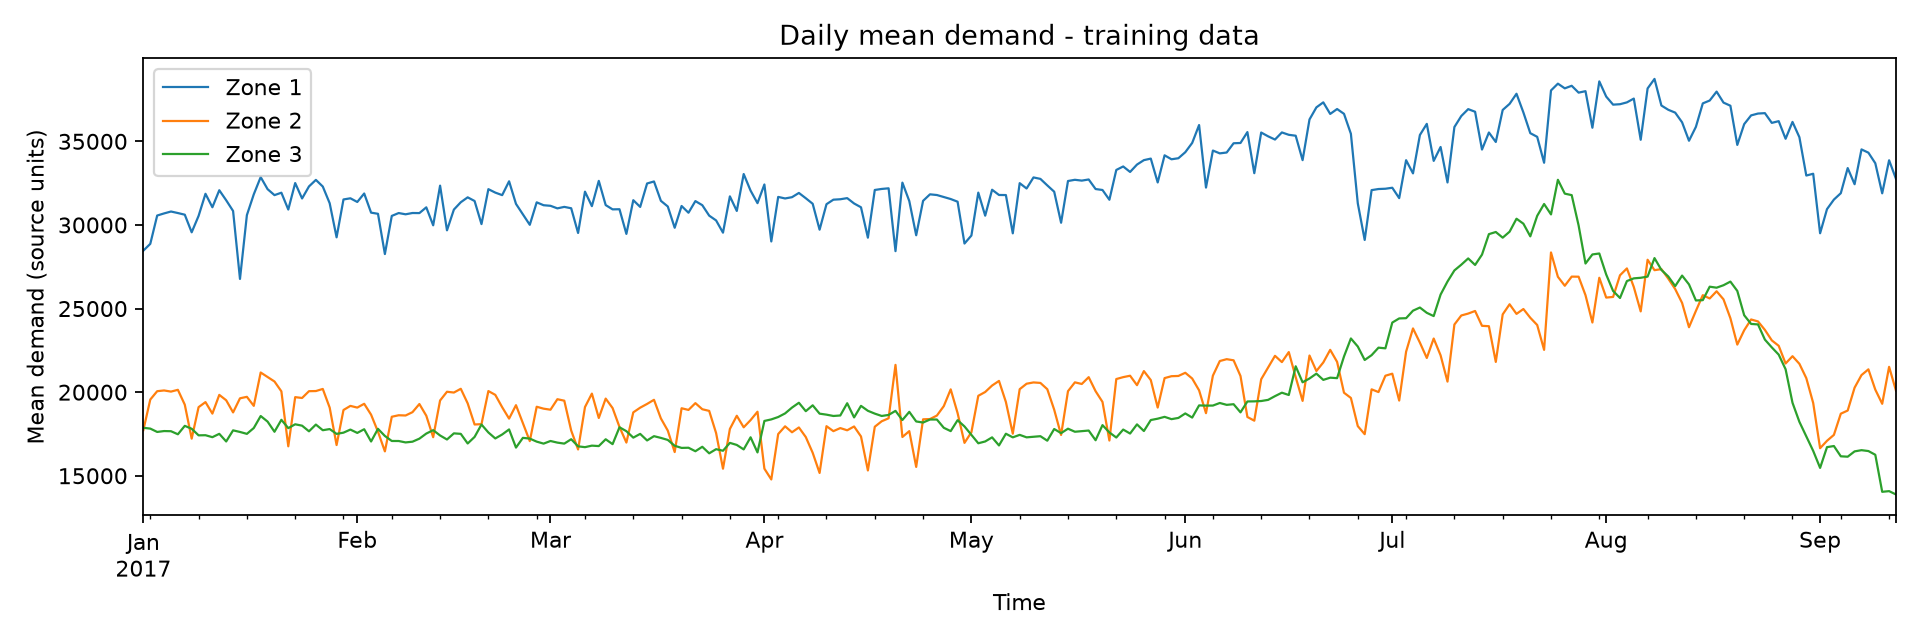

In [60]:
train_view = df.iloc[:train_end]
daily_power = train_view.set_index('time')[zones].resample('D').mean()
daily_power.plot(figsize=(12, 4), linewidth=1)
plt.title('Daily mean demand - training data')
plt.xlabel('Time')
plt.ylabel('Mean demand (source units)')
plt.legend(['Zone 1', 'Zone 2', 'Zone 3'])
plt.tight_layout()
plt.show()


### Training data checks
The file has no missing values, duplicate timestamps or gaps in the ten-minute grid. Explore patterns on train.


In [61]:
assert df.notna().all().all() and np.isfinite(df[weather + zones]).all().all()
assert not df.time.duplicated().any()
assert df.time.diff().dropna().eq(pd.Timedelta(minutes=10)).all()


### Training statistics
Compare the level and spread of the eight measured variables.


In [62]:
early = df.iloc[:train_end]
display(early[weather + zones].describe().T)


,count,mean,std,min,25%,50%,75%,max
temperature,"36,691.0000",19.2393,6.1815,3.2470,14.3400,19.1600,24.0400,40.0100
humidity,"36,691.0000",67.6561,16.0826,11.3400,57.3800,69.5200,81.4000,93.6000
wind_speed,"36,691.0000",1.9980,2.3575,0.0500,0.0770,0.0860,4.9130,4.9780
general_diffuse,"36,691.0000",207.6599,285.7269,0.0040,0.0660,18.2100,383.2000,"1,163.0000"
diffuse,"36,691.0000",86.5442,135.8819,0.0190,0.1260,16.4400,119.8000,936.0000
zone_1,"36,691.0000","32,956.8892","7,255.5949","13,895.6962","26,703.4233","33,089.3617","38,195.8804","52,204.3951"
zone_2,"36,691.0000","20,444.8429","5,067.7250","8,560.0815","16,298.7573","20,444.3506","23,875.6239","37,408.8608"
zone_3,"36,691.0000","20,024.4123","6,464.3840","8,189.9081","15,290.1818","18,071.6308","24,821.5674","47,598.3264"


### Hourly demand pattern
All three zones reach their highest average demand around 20:00.


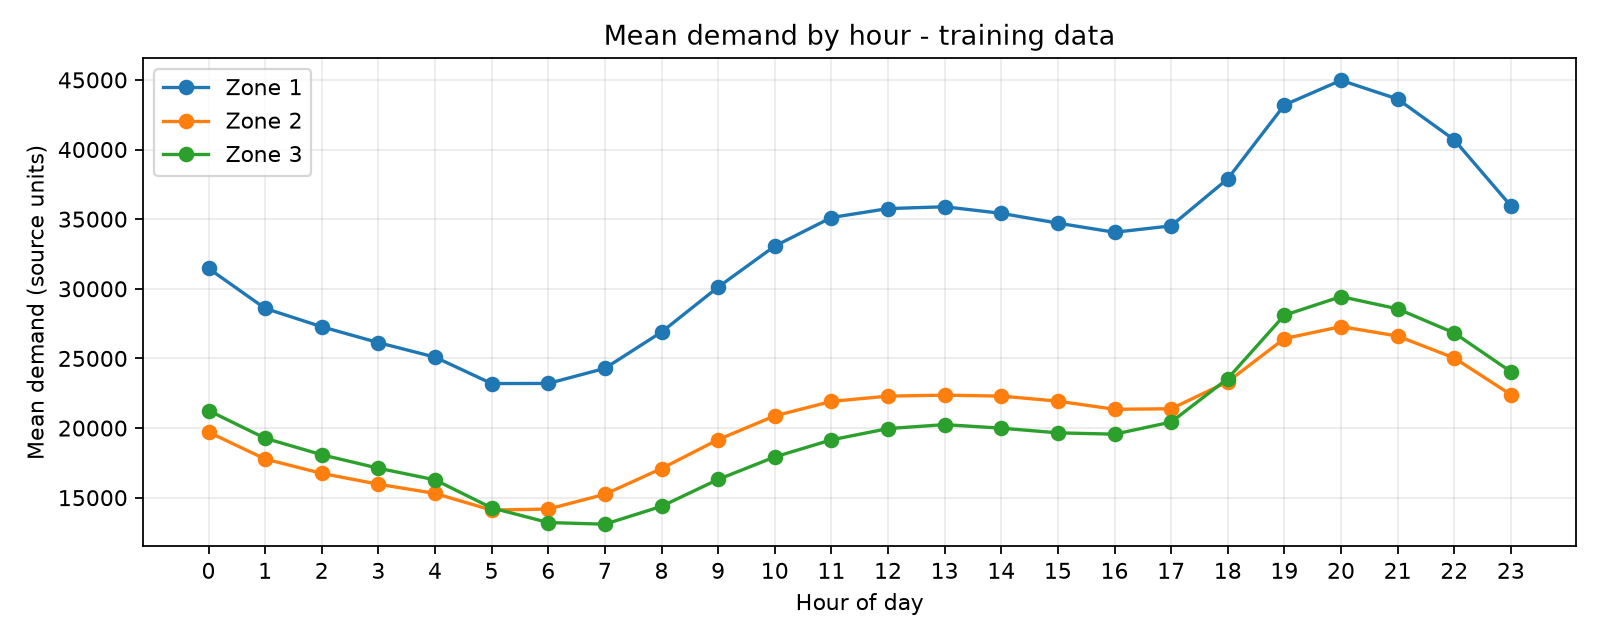

In [63]:
hourly_power = early.groupby(early.time.dt.hour)[zones].mean()
hourly_power.plot(marker='o', figsize=(10, 4))
plt.title('Mean demand by hour - training data')
plt.xlabel('Hour of day')
plt.ylabel('Mean demand (source units)')
plt.xticks(range(24))
plt.legend(['Zone 1', 'Zone 2', 'Zone 3'])
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


### Weekly demand pattern
Zones 1 and 2 have their lowest weekday averages on Sunday. Zone 3 follows a different weekly pattern.


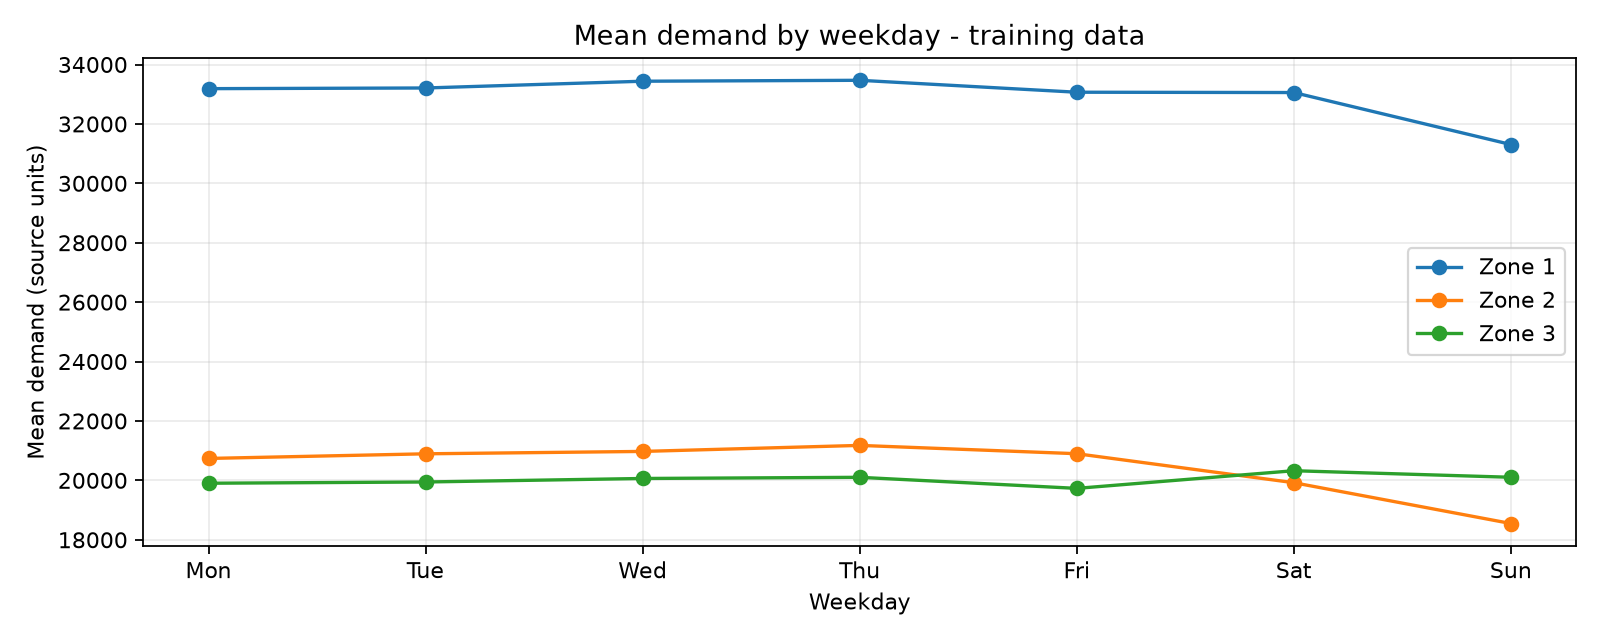

In [64]:
weekday_power = early.groupby(early.time.dt.dayofweek)[zones].mean()
weekday_power.plot(marker='o', figsize=(10, 4))
plt.title('Mean demand by weekday - training data')
plt.xlabel('Weekday')
plt.ylabel('Mean demand (source units)')
plt.xticks(range(7), ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
plt.legend(['Zone 1', 'Zone 2', 'Zone 3'])
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


### Monthly demand pattern
Zone 3 rises from about 20,431 in June to 28,194 in July. September covers September 1–12.


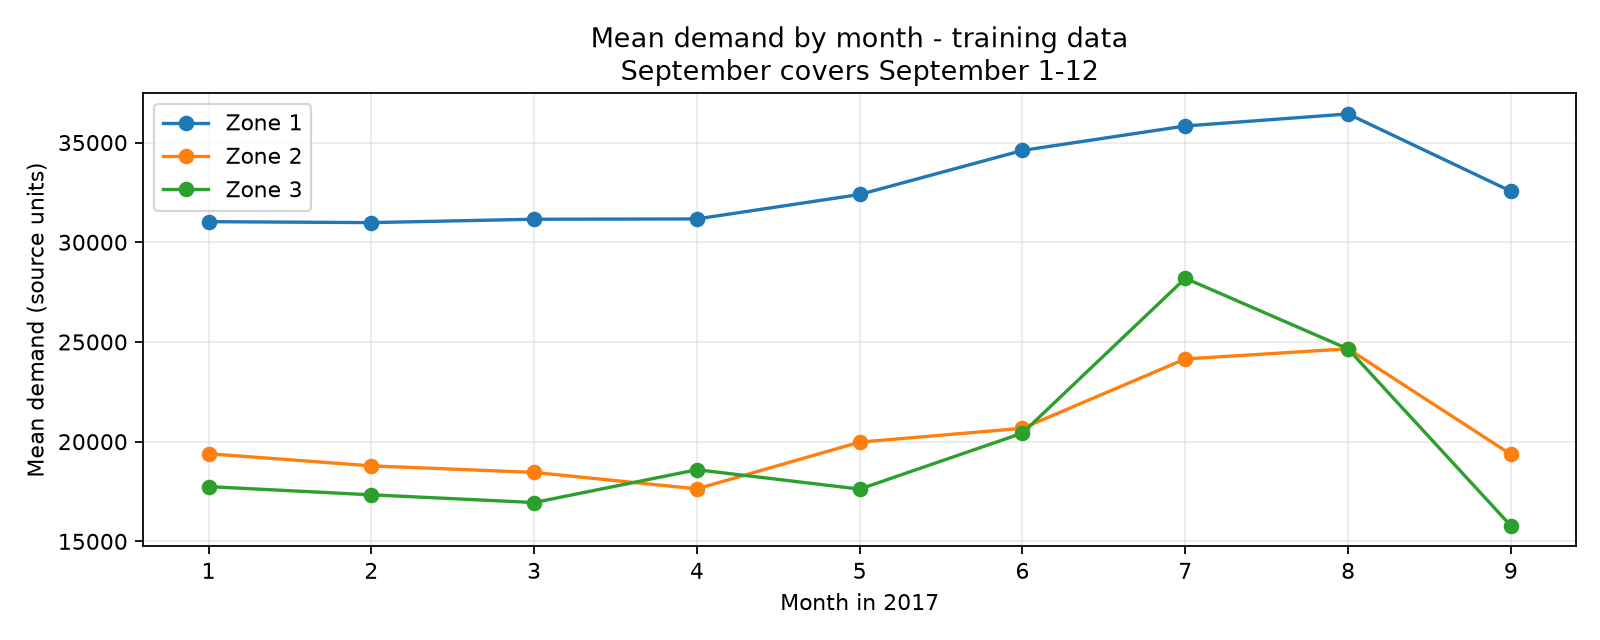

In [65]:
monthly_power = early.groupby(early.time.dt.month)[zones].mean()
monthly_power.plot(marker='o', figsize=(10, 4))
plt.title('Mean demand by month - training data\nSeptember covers September 1-12')
plt.xlabel('Month in 2017')
plt.ylabel('Mean demand (source units)')
plt.xticks(monthly_power.index)
plt.legend(['Zone 1', 'Zone 2', 'Zone 3'])
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 3. Eight current inputs
X contains five weather/radiation measurements and current demand in three zones. The target is demand ten minutes later.

Use the same target timestamps across all feature groups, starting when one month of history is available.


In [66]:
horizon = 1
time_step = df.time.diff().dropna().mode().iloc[0]
steps_per_day = int(pd.Timedelta(days=1) / time_step)
raw_columns = weather + zones
evaluation_start = df.time.iloc[0] + pd.DateOffset(months=1)
target_time = df.time + horizon * time_step
y = df[zones].shift(-horizon)
valid = (target_time >= evaluation_start) & y.notna().all(axis=1)
X, y = df.loc[valid, raw_columns], y.loc[valid]
origin, target_time = df.time.loc[valid], target_time.loc[valid]
validation_start = df.time.iloc[train_end]
train = target_time < validation_start
validation = origin >= validation_start
X_train_all, y_train = X.loc[train], y.loc[train]
X_val_all, y_val = X.loc[validation], y.loc[validation]
print('Time step:', time_step, '| Forecast horizon:', horizon * time_step)
print('Train:', len(y_train), '| Validation:', len(y_val))
assert target_time[train].max() < origin[validation].min()


Time step: 0 days 00:10:00 | Forecast horizon: 0 days 00:10:00
Train: 32227 | Validation: 7861


### Test inputs and targets
Make one next-step forecast at each origin using the measurements available at that time. Fit models and scalers on train.


In [67]:
test.columns = df.columns
test['time'] = pd.to_datetime(test['time'], format='%m/%d/%Y %H:%M')
assert test.time.diff().dropna().eq(time_step).all()
assert test.time.iloc[0] - df.time.iloc[-1] == time_step
assert test.notna().all().all() and np.isfinite(test[weather + zones]).all().all()
X_test_all = test[raw_columns].iloc[:-horizon].copy()
y_test = test[zones].shift(-horizon).iloc[:-horizon]
test_origin = test.time.iloc[:-horizon]
test_target_time = test_origin + horizon * time_step
assert target_time[validation].max() < test_origin.min()
print('Scored test rows:', len(y_test))


Scored test rows: 7862


### Evaluation metrics
MAE measures average absolute error; RMSE gives more weight to large errors. MAPE measures relative error, and R² compares squared error with predicting the mean. Use MAE for selection and give each zone equal weight.


In [68]:
def metrics(truth, predicted):
    return [mean_absolute_error(truth, predicted),
            np.sqrt(mean_squared_error(truth, predicted)),
            mean_absolute_percentage_error(truth, predicted) * 100,
            r2_score(truth, predicted)]

metric_names = ['MAE', 'RMSE', 'MAPE (%)', 'R2']

result_rows, step_tables = [], []
val_predictions, train_predictions, test_predictions = {}, {}, {}
candidates, candidate_columns = {}, {}
extra_models, extra_columns, delta_names = {}, {}, set()
result_columns = ['Model', 'Inputs'] + ['Validation ' + m for m in metric_names]
result_columns += ['Train ' + m for m in metric_names] + ['Test ' + m for m in metric_names]

def record_result(name, val_pred, train_pred, test_pred, count, eligible=True):
    if eligible:
        val_predictions[name] = val_pred
    train_predictions[name], test_predictions[name] = train_pred, test_pred
    result_rows.append([name, count, *metrics(y_val, val_pred), *metrics(y_train, train_pred), *metrics(y_test, test_pred)])

def compare_step(step, names, reference):
    results = pd.DataFrame(result_rows, columns=result_columns).set_index('Model')
    table = results.loc[names].copy()
    table['Test MAE reduction vs Persistence'] = results.loc['Persistence', 'Test MAE'] - table['Test MAE']
    table['Test MAE reduction vs ' + reference] = results.loc[reference, 'Test MAE'] - table['Test MAE']
    display(table.drop(columns=[c for c in table if c.startswith('Train ') or c in ['Validation RMSE', 'Validation MAPE (%)', 'Validation R2']]))
    step_tables.append(table.reset_index().assign(Step=step))


### Persistence baseline
Predict the next demand using the current value. Test MAE is 293.11 and R² is 0.9915. This is the benchmark for the learning models.


In [69]:
record_result('Persistence', X_val_all[zones].to_numpy(), X_train_all[zones].to_numpy(), X_test_all[zones].to_numpy(), 3)
compare_step('Persistence baseline', ['Persistence'], 'Persistence')


,Inputs,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Test MAE reduction vs Persistence
Model,,,,,,,
Persistence,3,295.4928,293.1130,456.7377,1.4608,0.9915,0.0000


## 4. Six models with eight inputs
Fit Linear, Ridge, Lasso, KNN, Decision Tree and Random Forest with their initial settings.

Persistence beats all six on validation MAE. Linear's test MAE is 301.56, above Persistence's 293.11.


In [70]:
models = {
    'Linear': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=100)),
    'Lasso': make_pipeline(StandardScaler(), Lasso(alpha=10, max_iter=200000, tol=0.001, precompute=True)),
    'KNN': make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=15, weights='distance', n_jobs=2)),
    'Decision Tree': DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=5, random_state=42, n_jobs=2),
}


In [71]:
simple_models = {}
for name, template in models.items():
    model = clone(template)
    model.fit(X_train_all[raw_columns], y_train)
    label = name + ' (8 inputs)'
    simple_models[label] = model
    candidates[label], candidate_columns[label] = model, raw_columns
    record_result(label, model.predict(X_val_all[raw_columns]), model.predict(X_train_all[raw_columns]), model.predict(X_test_all[raw_columns]), 8)
compare_step('Initial models', ['Persistence'] + list(simple_models), 'Persistence')


,Inputs,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Test MAE reduction vs Persistence
Model,,,,,,,
Persistence,3,295.4928,293.1130,456.7377,1.4608,0.9915,0.0000
Linear (8 inputs),8,313.1016,301.5586,453.2010,1.4963,0.9918,-8.4456
Ridge (8 inputs),8,338.6927,357.4468,499.8253,1.7941,0.9899,-64.3338
Lasso (8 inputs),8,299.0746,301.2296,453.7627,1.5274,0.9916,-8.1166
KNN (8 inputs),8,"1,721.7479","2,869.1284","3,513.6079",17.3113,0.2190,"-2,576.0154"
Decision Tree (8 inputs),8,"1,103.8269","2,224.0141","2,952.2267",12.7374,0.6075,"-1,930.9011"
Random Forest (8 inputs),8,873.5496,"1,914.0566","2,671.8124",11.1645,0.6796,"-1,620.9436"


## 5. Add recent history and clock features
Add demand lags, rolling means and standard deviations, daily references, and clock sine/cosine. Two clock coordinates keep times around midnight close.

The 40-input group reduces Linear's test MAE from 301.56 to 178.69.


In [72]:
def make_features(frame):
    future_time = frame.time + horizon * time_step
    X = frame[weather + zones].copy()
    for zone in zones:
        for lag in [1, 3, 6, 18, steps_per_day]:
            X[f'{zone}_lag_{lag}'] = frame[zone].shift(lag)
        for window in [6, 18]:
            X[f'{zone}_mean_{window}'] = frame[zone].rolling(window).mean()
            X[f'{zone}_std_{window}'] = frame[zone].rolling(window).std()
        X[f'{zone}_daily_reference'] = frame[zone].shift(steps_per_day - horizon)
        X[f'{zone}_weekly_lag'] = frame[zone].shift(7 * steps_per_day)
        X[f'{zone}_weekly_reference'] = frame[zone].shift(7 * steps_per_day - horizon)
        previous_month = future_time - pd.DateOffset(months=1)
        X[f'{zone}_monthly_reference'] = previous_month.map(frame.set_index('time')[zone])
    minute = future_time.dt.hour * 60 + future_time.dt.minute
    X['clock_sin'] = np.sin(2 * np.pi * minute / 1440)
    X['clock_cos'] = np.cos(2 * np.pi * minute / 1440)
    X['weekday_sin'] = np.sin(2 * np.pi * future_time.dt.dayofweek / 7)
    X['weekday_cos'] = np.cos(2 * np.pi * future_time.dt.dayofweek / 7)
    X['is_weekend'] = (future_time.dt.dayofweek >= 5).astype(float)
    X['month_sin'] = np.sin(2 * np.pi * (future_time.dt.month - 1) / 12)
    X['month_cos'] = np.cos(2 * np.pi * (future_time.dt.month - 1) / 12)
    phase = (future_time.dt.day - 1) / future_time.dt.days_in_month
    X['month_day_sin'] = np.sin(2 * np.pi * phase)
    X['month_day_cos'] = np.cos(2 * np.pi * phase)
    y = frame[zones].shift(-horizon)
    valid = X.notna().all(axis=1) & y.notna().all(axis=1)
    return X.loc[valid], y.loc[valid], frame.time.loc[valid], future_time.loc[valid]

X, y, origin, target_time = make_features(df)
print('Time step:', time_step, '| Forecast horizon:', horizon * time_step)
print('Inputs with week and month features:', X.shape[1])
display(X.head(2))


Time step: 0 days 00:10:00 | Forecast horizon: 0 days 00:10:00
Inputs with week and month features: 56


,temperature,humidity,wind_speed,general_diffuse,diffuse,zone_1,zone_2,zone_3,zone_1_lag_1,zone_1_lag_3,...,zone_3_monthly_reference,clock_sin,clock_cos,weekday_sin,weekday_cos,is_weekend,month_sin,month_cos,month_day_sin,month_day_cos
4463,11.4700,69.6300,4.9210,0.0480,0.1520,"31,084.5570","19,225.5319","19,477.5904","31,837.9747","33,685.0633",...,"20,240.9639",0.0000,1.0000,0.9749,-0.2225,0.0000,0.5000,0.8660,0.0000,1.0000
4464,11.5700,66.2600,4.9150,0.0590,0.1190,"29,892.2034","18,729.4833","18,848.8040","31,084.5570","32,688.6076",...,"20,131.0843",0.0436,0.9990,0.9749,-0.2225,0.0000,0.5000,0.8660,0.0000,1.0000


In [73]:
old_train_index, old_val_index, old_test_index = X_train_all.index, X_val_all.index, X_test_all.index
validation_start = df.time.iloc[train_end]
train, validation = target_time < validation_start, origin >= validation_start
X_train_all, y_train = X.loc[train], y.loc[train]
X_val_all, y_val = X.loc[validation], y.loc[validation]
test_history = pd.concat([df.tail(32 * steps_per_day), test])
X_test_all, y_test, test_origin, test_target_time = make_features(test_history)
in_test = test_origin >= test.time.iloc[0]
X_test_all, y_test = X_test_all.loc[in_test], y_test.loc[in_test]
test_origin, test_target_time = test_origin.loc[in_test], test_target_time.loc[in_test]
assert X_train_all.index.equals(old_train_index) and X_val_all.index.equals(old_val_index)
assert X_test_all.index.equals(old_test_index)
weekly = [c for c in X if 'weekly_' in c or c.startswith('weekday_') or c == 'is_weekend']
monthly = [c for c in X if 'monthly_' in c or c.startswith('month_')]
short = [c for c in X if c not in weekly + monthly]
short_model = make_pipeline(StandardScaler(), LinearRegression())
short_model.fit(X_train_all[short], y_train)
candidates['Linear (40 inputs)'], candidate_columns['Linear (40 inputs)'] = short_model, short
record_result('Linear (40 inputs)', short_model.predict(X_val_all[short]), short_model.predict(X_train_all[short]), short_model.predict(X_test_all[short]), len(short))
compare_step('Add history and clock', ['Persistence', 'Linear (8 inputs)', 'Linear (40 inputs)'], 'Linear (8 inputs)')


,Inputs,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Test MAE reduction vs Persistence,Test MAE reduction vs Linear (8 inputs)
Model,,,,,,,,
Persistence,3,295.4928,293.1130,456.7377,1.4608,0.9915,0.0000,8.4456
Linear (8 inputs),8,313.1016,301.5586,453.2010,1.4963,0.9918,-8.4456,0.0000
Linear (40 inputs),40,166.4142,178.6915,278.4380,0.9275,0.9965,114.4215,122.8672


## 6. Select inputs for each model
Compare short-term, + week, + month and both groups using validation MAE.

Linear and Ridge select + week; Lasso and Decision Tree select + month; KNN and Random Forest select short-term.


In [74]:
feature_sets = {'Short-term': short, '+ Week': short + weekly, '+ Month': short + monthly, '+ Week and month': list(X.columns)}
season_rows, season_models = [], {}
for model_name, template in models.items():
    for group_name, columns in feature_sets.items():
        model = clone(template)
        model.fit(X_train_all[columns], y_train)
        error = mean_absolute_error(y_val, model.predict(X_val_all[columns]))
        season_models[model_name, group_name] = model
        season_rows.append([model_name, group_name, len(columns), error])
seasonality = pd.DataFrame(season_rows, columns=['Model', 'Input group', 'Inputs', 'Validation MAE'])
selected_groups, model_columns, selected_rows = {}, {}, []
for name in models:
    table = seasonality.loc[seasonality['Model'] == name]
    best = table.loc[table['Validation MAE'].idxmin()]
    group = best['Input group']
    selected_groups[name], model_columns[name] = group, feature_sets[group]
    selected_rows.append(best)
selected_features = pd.DataFrame(selected_rows).set_index('Model')
display(seasonality.pivot(index='Model', columns='Input group', values='Validation MAE'))
display(selected_features)


Input group,+ Month,+ Week,+ Week and month,Short-term
Model,,,,
Decision Tree,"1,116.6321","1,118.3675","1,118.7698","1,116.9190"
KNN,"1,677.3792","1,837.1900","1,801.4908","1,619.4868"
Lasso,221.0035,223.5357,224.7901,222.2190
Linear,168.1104,163.7002,165.4323,166.4142
Random Forest,941.0476,941.2051,948.5444,939.0575
Ridge,225.6683,210.9964,220.0876,215.7443


,Input group,Inputs,Validation MAE
Model,,,
Linear,+ Week,49,163.7002
Ridge,+ Week,49,210.9964
Lasso,+ Month,47,221.0035
KNN,Short-term,40,"1,619.4868"
Decision Tree,+ Month,47,"1,116.6321"
Random Forest,Short-term,40,939.0575


### Compare selected inputs with eight inputs
Compare each model with its eight-input version. Add previous-day, previous-week and previous-month baselines. Persistence beats these seasonal baselines at the ten-minute horizon.


In [75]:
baseline_columns = {
    'Persistence': zones,
    'Previous day': [f'{z}_daily_reference' for z in zones],
    'Previous week': [f'{z}_weekly_reference' for z in zones],
    'Previous month': [f'{z}_monthly_reference' for z in zones]
}
for name, columns in baseline_columns.items():
    if name != 'Persistence':
        record_result(name, X_val_all[columns].to_numpy(), X_train_all[columns].to_numpy(), X_test_all[columns].to_numpy(), len(columns))
for name in models:
    columns = model_columns[name]
    model = season_models[name, selected_groups[name]]
    candidates[name], candidate_columns[name] = model, columns
    record_result(name, model.predict(X_val_all[columns]), model.predict(X_train_all[columns]), model.predict(X_test_all[columns]), len(columns))
initial_results = pd.DataFrame([[name, *metrics(y_val, val_predictions[name])] for name in models], columns=['Model'] + metric_names).set_index('Model')
compare_step('Inputs selected per model', list(simple_models) + list(models), 'Linear (8 inputs)')


,Inputs,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Test MAE reduction vs Persistence,Test MAE reduction vs Linear (8 inputs)
Model,,,,,,,,
Linear (8 inputs),8,313.1016,301.5586,453.2010,1.4963,0.9918,-8.4456,0.0000
Ridge (8 inputs),8,338.6927,357.4468,499.8253,1.7941,0.9899,-64.3338,-55.8882
Lasso (8 inputs),8,299.0746,301.2296,453.7627,1.5274,0.9916,-8.1166,0.3290
KNN (8 inputs),8,"1,721.7479","2,869.1284","3,513.6079",17.3113,0.2190,"-2,576.0154","-2,567.5697"
Decision Tree (8 inputs),8,"1,103.8269","2,224.0141","2,952.2267",12.7374,0.6075,"-1,930.9011","-1,922.4555"
Random Forest (8 inputs),8,873.5496,"1,914.0566","2,671.8124",11.1645,0.6796,"-1,620.9436","-1,612.4980"
Linear,49,163.7002,173.5309,271.3365,0.8951,0.9967,119.5821,128.0277
Ridge,49,210.9964,255.5105,366.1971,1.3066,0.9940,37.6025,46.0481
Lasso,47,221.0035,268.1456,384.9544,1.3524,0.9938,24.9674,33.4131


## 7. Tune model parameters
Keep each model's selected input group. Choose parameters by MAE over three expanding CV folds within train, with a one-row gap.


In [76]:
cv = TimeSeriesSplit(n_splits=3, gap=horizon)
tuned, searches, tuning_rows = {}, {}, []

def tune_model(name, grid):
    columns = model_columns[name]
    search = GridSearchCV(models[name], grid, scoring='neg_mean_absolute_error', cv=cv, n_jobs=1, error_score='raise')
    search.fit(X_train_all[columns], y_train)
    model = search.best_estimator_
    tuned[name], searches[name] = model, search
    label = name + ' (tuned)'
    candidates[label], candidate_columns[label] = model, columns
    val_pred = model.predict(X_val_all[columns])
    record_result(label, val_pred, model.predict(X_train_all[columns]), model.predict(X_test_all[columns]), len(columns))
    tuning_rows.append([name, selected_groups[name], search.best_params_, -search.best_score_, mean_absolute_error(y_val, val_pred)])
    print(name, '| Input group:', selected_groups[name], '| Parameters:', search.best_params_, '| CV MAE:', -search.best_score_)
    compare_step('Parameter tuning - ' + name, [name, label], name)


### Ridge and Lasso
Ridge selects alpha = 0.001 and closely matches Linear. Lasso selects alpha = 0.1.


In [77]:
tune_model('Ridge', {'ridge__alpha': [0.001, 0.1, 1, 10, 100, 1000]})
tune_model('Lasso', {'lasso__alpha': [0.1, 1, 10, 100]})


Ridge | Input group: + Week | Parameters: {'ridge__alpha': 0.001} | CV MAE: 185.91970627293196


,Inputs,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Test MAE reduction vs Persistence,Test MAE reduction vs Ridge
Model,,,,,,,,
Ridge,49,210.9964,255.5105,366.1971,1.3066,0.9940,37.6025,0.0000
Ridge (tuned),49,163.7004,173.5318,271.3373,0.8951,0.9967,119.5812,81.9787


Lasso | Input group: + Month | Parameters: {'lasso__alpha': 0.1} | CV MAE: 204.227378008203


,Inputs,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Test MAE reduction vs Persistence,Test MAE reduction vs Lasso
Model,,,,,,,,
Lasso,47,221.0035,268.1456,384.9544,1.3524,0.9938,24.9674,0.0000
Lasso (tuned),47,182.5659,197.9172,303.1945,1.0875,0.9952,95.1958,70.2284


### KNN neighbour count
K = 9 gives the lowest CV MAE. Its validation MAE is 1,580.17.


KNN | Input group: Short-term | Parameters: {'kneighborsregressor__n_neighbors': 9} | CV MAE: 1306.0138827723174


,Inputs,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Test MAE reduction vs Persistence,Test MAE reduction vs KNN
Model,,,,,,,,
KNN,40,"1,619.4868","2,935.7419","3,322.9152",17.1139,0.3995,"-2,642.6289",0.0000
KNN (tuned),40,"1,580.1727","2,823.2522","3,249.4287",16.2388,0.4510,"-2,530.1392",112.4897


,K,CV MAE
0,3,"1,326.9997"
1,5,"1,311.3698"
2,9,"1,306.0139"
3,15,"1,311.5358"
4,21,"1,321.0308"
5,31,"1,336.0023"


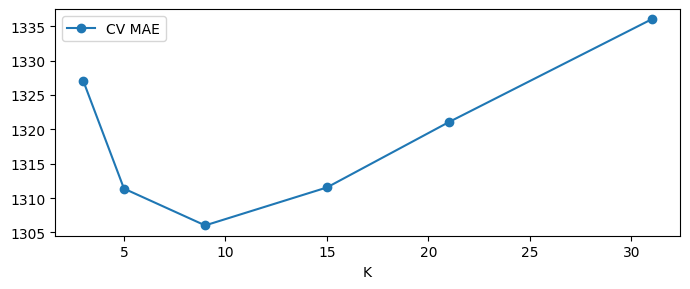

In [78]:
tune_model('KNN', {'kneighborsregressor__n_neighbors': [3, 5, 9, 15, 21, 31]})
search = searches['KNN']
k_scores = pd.DataFrame({'K': search.cv_results_['param_kneighborsregressor__n_neighbors'],
                         'CV MAE': -search.cv_results_['mean_test_score']})
display(k_scores)
k_scores.plot(x='K', y='CV MAE', marker='o', figsize=(7, 3))
plt.tight_layout()
plt.show()


### Decision Tree and Random Forest
Both select unlimited depth. Decision Tree uses a minimum leaf size of 5; Random Forest uses 2 and keeps 60 trees.


In [79]:
tune_model('Decision Tree', {'max_depth': [6, 12, 18, None], 'min_samples_leaf': [5, 20]})
tune_model('Random Forest', {'max_depth': [10, 18, None], 'min_samples_leaf': [2, 10]})


Decision Tree | Input group: + Month | Parameters: {'max_depth': None, 'min_samples_leaf': 5} | CV MAE: 968.4418684281394


,Inputs,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Test MAE reduction vs Persistence,Test MAE reduction vs Decision Tree
Model,,,,,,,,
Decision Tree,47,"1,116.6321","2,153.5567","2,997.9611",12.3426,0.6073,"-1,860.4437",0.0000
Decision Tree (tuned),47,"1,034.2399","1,969.3330","2,894.5425",10.7910,0.6597,"-1,676.2200",184.2236


Random Forest | Input group: Short-term | Parameters: {'max_depth': None, 'min_samples_leaf': 2} | CV MAE: 743.6879072149413


,Inputs,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Test MAE reduction vs Persistence,Test MAE reduction vs Random Forest
Model,,,,,,,,
Random Forest,40,939.0575,"1,954.2987","2,818.6677",11.0177,0.6670,"-1,661.1857",0.0000
Random Forest (tuned),40,906.5497,"1,865.9388","2,713.3682",10.3759,0.6967,"-1,572.8258",88.3599


### Tuning results
Tuning improves validation MAE for all five models. Ridge gives the largest reduction, from 211.00 to 163.70.


In [80]:
tuning_results = pd.DataFrame(tuning_rows, columns=['Model', 'Input group', 'Selected parameters', 'CV MAE', 'Validation MAE'])
display(tuning_results)


,Model,Input group,Selected parameters,CV MAE,Validation MAE
0,Ridge,+ Week,{'ridge__alpha': 0.001},185.9197,163.7004
1,Lasso,+ Month,{'lasso__alpha': 0.1},204.2274,182.5659
2,KNN,Short-term,{'kneighborsregressor__n_neighbors': 9},"1,306.0139","1,580.1727"
3,Decision Tree,+ Month,"{'max_depth': None, 'min_samples_leaf': 5}",968.4419,"1,034.2399"
4,Random Forest,Short-term,"{'max_depth': None, 'min_samples_leaf': 2}",743.6879,906.5497


## 8. Predict the demand change
Keep the tuned RF inputs and settings. Train on next demand minus current demand, then add the predicted change to the current level.

Validation MAE falls from 906.55 to 191.34, a 78.9% reduction.


In [81]:
delta_train = y_train.to_numpy() - X_train_all[zones].to_numpy()
delta_names, delta_rows = set(), []
for name in ['Random Forest']:
    columns = model_columns[name]
    model = clone(tuned[name])
    cv_errors = -cross_val_score(model, X_train_all[columns], delta_train, scoring='neg_mean_absolute_error',
                                 cv=cv, n_jobs=1, error_score='raise')
    model.fit(X_train_all[columns], delta_train)
    label = name + ' (delta)'
    predicted = X_val_all[zones].to_numpy() + model.predict(X_val_all[columns])
    extra_models[label], extra_columns[label] = model, columns
    delta_names.add(label)
    val_predictions[label] = predicted
    before_mae = mean_absolute_error(y_val, val_predictions[name + ' (tuned)'])
    candidates[label], candidate_columns[label] = model, columns
    record_result(label, predicted, X_train_all[zones].to_numpy() + model.predict(X_train_all[columns]), X_test_all[zones].to_numpy() + model.predict(X_test_all[columns]), len(columns))
    compare_step('Predict changes - ' + name, [name + ' (tuned)', label], name + ' (tuned)')
    delta_rows.append([label, before_mae, cv_errors.mean(), cv_errors.std(), *metrics(y_val, predicted)])
delta_results = pd.DataFrame(delta_rows, columns=['Model', 'Previous validation MAE', 'Delta CV MAE', 'CV MAE std'] + metric_names).set_index('Model')
display(delta_results)


,Inputs,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Test MAE reduction vs Persistence,Test MAE reduction vs Random Forest (tuned)
Model,,,,,,,,
Random Forest (tuned),40,906.5497,"1,865.9388","2,713.3682",10.3759,0.6967,"-1,572.8258",0.0000
Random Forest (delta),40,191.3375,247.7419,375.4480,1.2691,0.9942,45.3711,"1,618.1969"


,Previous validation MAE,Delta CV MAE,CV MAE std,MAE,RMSE,MAPE (%),R2
Model,,,,,,,
Random Forest (delta),906.5497,254.5722,56.9274,191.3375,295.8678,0.9357,0.9961


## 9. Remove input groups
Test seven reductions for Linear. Accept a reduction when both CV MAE and validation MAE fall.

Keep all 49 inputs: none of the reductions improves both scores.


In [82]:
selected_columns = model_columns['Linear']
removals = {
    'Remove weather': weather,
    'Remove rolling std': [c for c in selected_columns if '_std_' in c],
    'Remove rolling mean': [c for c in selected_columns if '_mean_' in c],
    'Remove all rolling': [c for c in selected_columns if '_std_' in c or '_mean_' in c],
    'Remove lags 3/6/18': [f'{z}_lag_{lag}' for z in zones for lag in [3, 6, 18]],
    'Remove weekly demand history': [c for c in selected_columns if '_weekly_' in c]
}
ablation_columns = {'Full model': selected_columns}
for name, removed in removals.items():
    ablation_columns[name] = [c for c in selected_columns if c not in removed]
compact = zones + [f'{z}_lag_{lag}' for z in zones for lag in [1, 3]]
compact += [c for c in selected_columns if '_mean_' in c]
compact += ['clock_sin', 'clock_cos', 'weekday_sin', 'weekday_cos', 'is_weekend']
compact += [f'{z}_daily_reference' for z in zones] + [f'{z}_weekly_reference' for z in zones]
compact = [c for c in dict.fromkeys(compact) if c in selected_columns]
ablation_columns['Compact subset'] = compact
feature_models, feature_predictions, feature_rows = {}, {}, []
for name, columns in ablation_columns.items():
    model = make_pipeline(StandardScaler(), LinearRegression())
    cv_errors = -cross_val_score(model, X_train_all[columns], y_train,
                                 scoring='neg_mean_absolute_error', cv=cv, error_score='raise')
    model.fit(X_train_all[columns], y_train)
    predicted = model.predict(X_val_all[columns])
    feature_models[name], feature_predictions[name] = model, predicted
    record_result('Feature ablation - ' + name, predicted, model.predict(X_train_all[columns]), model.predict(X_test_all[columns]), len(columns), eligible=False)
    feature_rows.append([name, len(columns), cv_errors.mean(), cv_errors.std(), *metrics(y_val, predicted)])
feature_ablation = pd.DataFrame(feature_rows, columns=['Configuration', 'Inputs', 'CV MAE', 'CV MAE std'] + metric_names).set_index('Configuration')
display(feature_ablation)
reference = feature_ablation.loc['Full model']
approved_features = feature_ablation[(feature_ablation['CV MAE'] < reference['CV MAE']) & (feature_ablation.MAE < reference.MAE)]

for name in approved_features.index:
    label = 'Linear - ' + name
    extra_models[label], extra_columns[label] = feature_models[name], ablation_columns[name]
    val_predictions[label] = feature_predictions[name]
    candidates[label], candidate_columns[label] = feature_models[name], ablation_columns[name]
print('Reductions meeting both criteria:', approved_features.index.tolist())

compare_step('Remove input groups', ['Feature ablation - ' + name for name in ablation_columns], 'Linear')


,Inputs,CV MAE,CV MAE std,MAE,RMSE,MAPE (%),R2
Configuration,,,,,,,
Full model,49,185.9190,14.7062,163.7002,248.1691,0.7952,0.9972
Remove weather,44,186.1875,15.3739,163.6213,248.1589,0.7950,0.9972
Remove rolling std,43,184.4486,12.1606,163.9602,249.1129,0.7950,0.9971
Remove rolling mean,43,185.8556,14.7267,163.8047,248.2614,0.7955,0.9972
Remove all rolling,37,184.4378,12.1992,164.1016,249.2103,0.7954,0.9971
Remove lags 3/6/18,40,184.7321,13.1491,164.1011,248.7772,0.7972,0.9971
Remove weekly demand history,43,190.5180,15.0224,166.3398,250.6944,0.8131,0.9971
Compact subset,26,242.1579,41.5777,192.7679,290.6699,0.9285,0.9962


Reductions meeting both criteria: []


,Inputs,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Test MAE reduction vs Persistence,Test MAE reduction vs Linear
Model,,,,,,,,
Feature ablation - Full model,49,163.7002,173.5309,271.3365,0.8951,0.9967,119.5821,0.0000
Feature ablation - Remove weather,44,163.6213,174.1249,271.9064,0.8989,0.9966,118.9881,-0.5940
Feature ablation - Remove rolling std,43,163.9602,172.6010,270.2092,0.8912,0.9967,120.5120,0.9299
Feature ablation - Remove rolling mean,43,163.8047,173.6740,271.4489,0.8957,0.9967,119.4390,-0.1431
Feature ablation - Remove all rolling,37,164.1016,172.8067,270.3721,0.8923,0.9967,120.3063,0.7242
Feature ablation - Remove lags 3/6/18,40,164.1011,174.9067,272.6740,0.9021,0.9966,118.2063,-1.3758
Feature ablation - Remove weekly demand history,43,166.3398,178.6225,278.3417,0.9281,0.9965,114.4905,-5.0916
Feature ablation - Compact subset,26,192.7679,231.2248,336.4252,1.1917,0.9950,61.8882,-57.6939


## 10. Select the final model
Select Linear with 49 inputs from the retained candidates. Test MAE is 173.53, 40.8% below Persistence. Tuned Ridge gives almost the same result.


In [83]:
validation_rows = [[name, *metrics(y_val, predicted)] for name, predicted in val_predictions.items()]
validation_results = pd.DataFrame(validation_rows, columns=['Model'] + metric_names).set_index('Model').sort_values('MAE')
best_name = validation_results.index[0]
all_results = pd.DataFrame(result_rows, columns=result_columns).set_index('Model')
train_test_results = all_results.loc[validation_results.index, [c for c in all_results if c.startswith('Train ') or c.startswith('Test ')]]
best_test_prediction = test_predictions[best_name]
display(validation_results)
display(train_test_results)
print('Selected by validation:', best_name, '| Test rows:', len(y_test))
display(train_test_results.loc[[best_name]])
progress_table = pd.concat(step_tables, ignore_index=True)
zone_mae = pd.DataFrame({zone: {name: mean_absolute_error(y_test[zone], predicted[:, i]) for name, predicted in test_predictions.items()} for i, zone in enumerate(zones)})
display(zone_mae.loc[[best_name, 'Persistence']])


,MAE,RMSE,MAPE (%),R2
Model,,,,
Linear,163.7002,248.1691,0.7952,0.9972
Ridge (tuned),163.7004,248.1694,0.7952,0.9972
Linear (40 inputs),166.4142,250.8107,0.8133,0.9971
Lasso (tuned),182.5659,272.1750,0.9279,0.9960
Random Forest (delta),191.3375,295.8678,0.9357,0.9961
Ridge,210.9964,313.5944,1.0269,0.9954
Lasso,221.0035,343.2050,1.0557,0.9949
Persistence,295.4928,463.5863,1.3623,0.9910
Lasso (8 inputs),299.0746,459.8737,1.4044,0.9910


,Train MAE,Train RMSE,Train MAPE (%),Train R2,Test MAE,Test RMSE,Test MAPE (%),Test R2
Model,,,,,,,,
Linear,174.8728,280.6289,0.7539,0.9981,173.5309,271.3365,0.8951,0.9967
Ridge (tuned),174.8728,280.6289,0.7539,0.9981,173.5318,271.3373,0.8951,0.9967
Linear (40 inputs),179.1880,285.6638,0.7730,0.9980,178.6915,278.4380,0.9275,0.9965
Lasso (tuned),196.3784,305.6481,0.8599,0.9977,197.9172,303.1945,1.0875,0.9952
Random Forest (delta),83.0410,149.9439,0.3619,0.9994,247.7419,375.4480,1.2691,0.9942
Ridge,212.8458,331.6777,0.9173,0.9973,255.5105,366.1971,1.3066,0.9940
Lasso,236.5682,375.1909,1.0099,0.9966,268.1456,384.9544,1.3524,0.9938
Persistence,348.0153,523.9934,1.4638,0.9934,293.1130,456.7377,1.4608,0.9915
Lasso (8 inputs),328.6891,505.9308,1.3866,0.9938,301.2296,453.7627,1.5274,0.9916


Selected by validation: Linear | Test rows: 7862


,Train MAE,Train RMSE,Train MAPE (%),Train R2,Test MAE,Test RMSE,Test MAPE (%),Test R2
Model,,,,,,,,
Linear,174.8728,280.6289,0.7539,0.9981,173.5309,271.3365,0.8951,0.9967


,zone_1,zone_2,zone_3
Linear,220.1709,161.9985,138.4233
Persistence,364.3591,312.3959,202.5840


### 10.1. Standard AR and VAR references
Compare Linear's 49-input design with two established forecasting models. AR uses a zone's own recent demand; VAR uses recent demand from all three zones. Both predict the next ten-minute reading.

Use the same training rows and scored validation/test timestamps as the six-model experiment. Select each lag order by three-fold expanding CV within train. These references supplement the model selected above.

Source: Hyndman and Athanasopoulos, *Forecasting: Principles and Practice*, [autoregressive models](https://otexts.com/fpp3/arima.html#autoregressive-models) and [vector autoregressions](https://otexts.com/fpp3/advanced.html#vector-autoregressions).


In [12]:
arvar_orders = [1, 3, 6, 12, 18, 36]
arvar_history = pd.concat([df, test])
arvar_y = pd.concat([y_train, y_val, y_test]).sort_index()
arvar_indices = {'Train': y_train.index, 'Validation': y_val.index, 'Test': y_test.index}
assert arvar_history.index.is_unique and arvar_y.index.is_unique
pd.testing.assert_frame_equal(arvar_history[zones].shift(-horizon).loc[arvar_y.index], arvar_y)

# Lag 0 is the current measurement; lag 1 is ten minutes earlier.
arvar_lags = {}
for zone in zones:
    arvar_lags[zone] = pd.concat(
        [arvar_history[zone].shift(k).rename(f'{zone}_lag_{k}')
         for k in range(max(arvar_orders))], axis=1).loc[arvar_y.index]
    assert arvar_lags[zone].notna().all().all()

def arvar_inputs(order):
    return pd.concat([arvar_lags[zone].iloc[:, :order] for zone in zones], axis=1)

def fit_arvar(method, order, fit_index):
    if method == 'AR':
        fitted = {}
        for zone in zones:
            model = make_pipeline(StandardScaler(), LinearRegression())
            model.fit(arvar_lags[zone].loc[fit_index].iloc[:, :order],
                      arvar_y.loc[fit_index, zone])
            fitted[zone] = model
        return fitted
    model = make_pipeline(StandardScaler(), LinearRegression())
    model.fit(arvar_inputs(order).loc[fit_index], arvar_y.loc[fit_index, zones])
    return model

def predict_arvar(method, order, fitted, index):
    if method == 'AR':
        return np.column_stack([
            fitted[zone].predict(arvar_lags[zone].loc[index].iloc[:, :order])
            for zone in zones])
    return fitted.predict(arvar_inputs(order).loc[index])

display(pd.DataFrame({'Rows': {name: len(index) for name, index in arvar_indices.items()}}))


,Rows
Train,32227
Validation,7861
Test,7862


### 10.2. Select the lag order
Try orders 1, 3, 6, 12, 18 and 36. For each order, average MAE across the three zones and three CV folds. Fit every scaler on its fold's training rows. Select AR and VAR separately by the lowest mean CV MAE.


In [13]:
arvar_cv = TimeSeriesSplit(n_splits=3, gap=horizon)
arvar_cv_rows = []
for method in ['AR', 'VAR']:
    for order in arvar_orders:
        fold_mae = []
        for fold, (fit_positions, score_positions) in enumerate(arvar_cv.split(y_train), start=1):
            fit_index = y_train.index[fit_positions]
            score_index = y_train.index[score_positions]
            fitted = fit_arvar(method, order, fit_index)
            prediction = predict_arvar(method, order, fitted, score_index)
            fold_mae.append(mean_absolute_error(arvar_y.loc[score_index, zones], prediction))
        arvar_cv_rows.append([method, order, *fold_mae, np.mean(fold_mae)])
arvar_cv_results = pd.DataFrame(arvar_cv_rows,
    columns=['Model', 'Order', 'Fold 1 MAE', 'Fold 2 MAE', 'Fold 3 MAE', 'CV MAE'])
arvar_selected = arvar_cv_results.loc[
    arvar_cv_results.groupby('Model')['CV MAE'].idxmin()].set_index('Model')
display(arvar_cv_results.pivot(index='Order', columns='Model', values='CV MAE'))
display(arvar_selected[['Order', 'CV MAE']])


Model,AR,VAR
Order,,
1,350.3129,356.9427
3,232.5867,223.7049
6,231.2147,222.9327
12,230.7398,222.8963
18,231.1177,224.7960
36,231.9202,230.2522


,Order,CV MAE
Model,,
AR,12,230.7398
VAR,12,222.8963


### 10.3. Compare the selected references with Linear
Both searches select order 12. Refit each reference on all training rows, then calculate validation and test MAE. AR(12) uses 12 inputs per zone; VAR(12) uses 36 inputs in each output equation. Linear uses the 49 inputs selected earlier.


In [14]:
arvar_selected_fits, arvar_predictions = {}, {}
comparison_rows = [
    ['Persistence', mean_absolute_error(y_val, val_predictions['Persistence']),
     mean_absolute_error(y_test, test_predictions['Persistence'])]]
for method in ['AR', 'VAR']:
    order = int(arvar_selected.loc[method, 'Order'])
    fitted = fit_arvar(method, order, y_train.index)
    arvar_selected_fits[method] = fitted
    scores = []
    for split in ['Validation', 'Test']:
        index = arvar_indices[split]
        prediction = predict_arvar(method, order, fitted, index)
        arvar_predictions[method, split] = prediction
        scores.append(mean_absolute_error(arvar_y.loc[index, zones], prediction))
    comparison_rows.append([f'{method}({order})', *scores])
linear_label = f'Linear ({len(model_columns["Linear"])} inputs)'
comparison_rows.append([linear_label,
    mean_absolute_error(y_val, val_predictions['Linear']),
    mean_absolute_error(y_test, test_predictions['Linear'])])
arvar_comparison = pd.DataFrame(comparison_rows,
    columns=['Model', 'Validation MAE', 'Test MAE']).set_index('Model')
display(arvar_comparison)
for method in ['AR', 'VAR']:
    label = f'{method}({int(arvar_selected.loc[method, "Order"])})'
    reduction = 100 * (1 - arvar_comparison.loc[linear_label, 'Test MAE'] /
                       arvar_comparison.loc[label, 'Test MAE'])
    print(f'Linear test MAE reduction vs {label}: {reduction:.1f}%')


,Validation MAE,Test MAE
Model,,
Persistence,295.4928,293.1130
AR(12),203.3488,208.0750
VAR(12),196.2484,226.5171
Linear (49 inputs),163.7002,173.5309


Linear test MAE reduction vs AR(12): 16.6%
Linear test MAE reduction vs VAR(12): 23.4%


Linear's test MAE is 173.53, compared with 208.07 for AR(12) and 226.52 for VAR(12): reductions of 16.6% and 23.4%. It also has lower validation MAE than both references. The result supports the full 49-input design, which combines recent and seasonal demand history, rolling summaries, calendar features and current weather.

VAR beats AR on CV and validation but has higher test MAE. Adding cross-zone history does not improve every period. These results compare the specifications and split used here.


## 11. Error over time
Plot weekly and monthly MAE for Persistence and the top three validation models. Linear beats Persistence in all eight test weeks. Its monthly MAE is 184.90 in November and 164.21 in December.


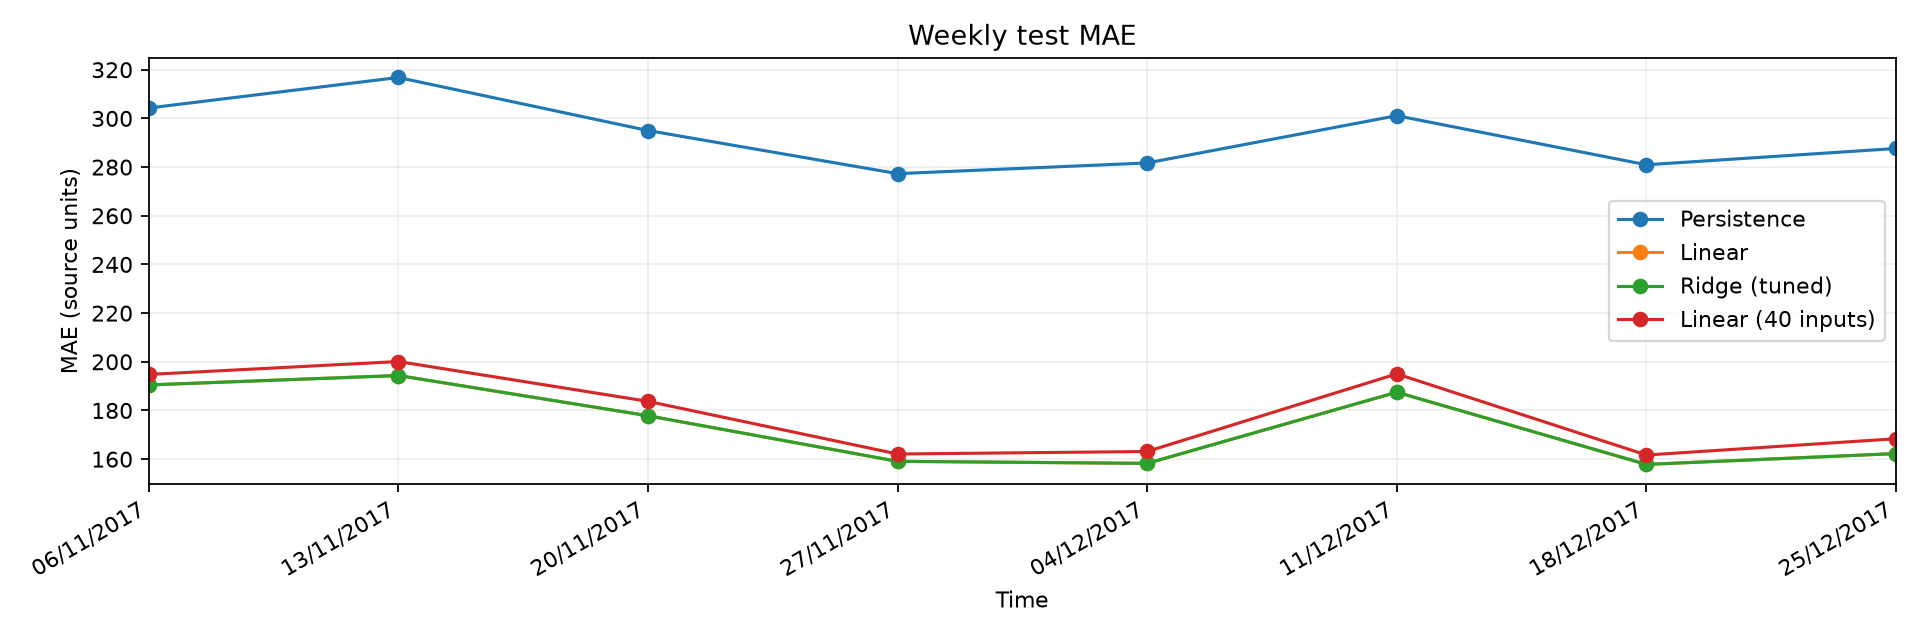

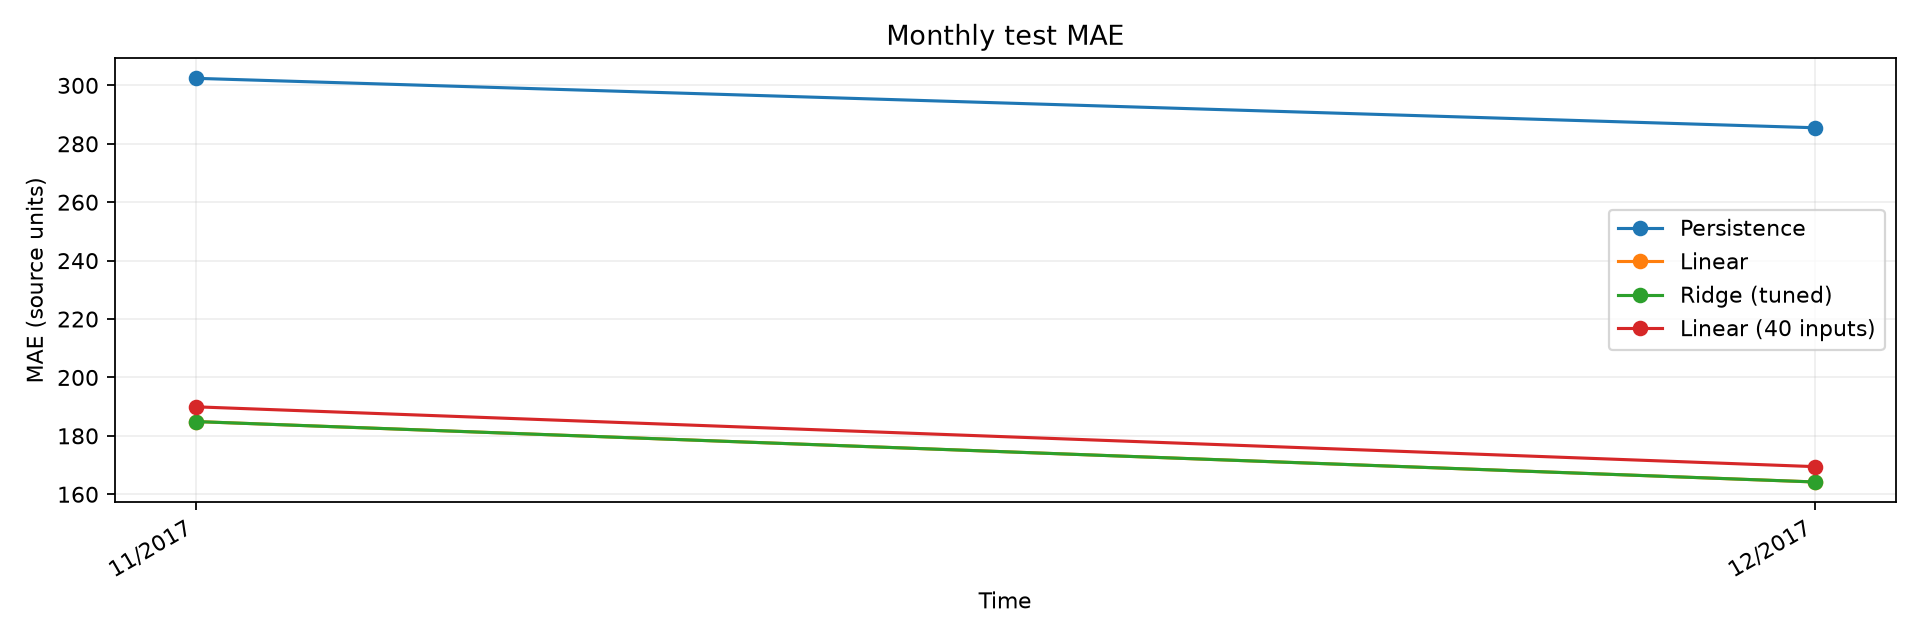

In [ ]:
row_errors = {name: np.abs(y_test.to_numpy() - predicted).mean(axis=1)
              for name, predicted in test_predictions.items()}
errors_by_time = pd.DataFrame(row_errors, index=pd.DatetimeIndex(test_target_time, name='Target time'))
weekly_mae = errors_by_time.groupby(errors_by_time.index.to_period('W')).mean()
monthly_mae = errors_by_time.groupby(errors_by_time.index.to_period('M')).mean()
show_models = list(dict.fromkeys(['Persistence'] + validation_results.index[:3].tolist()))
for table, title, filename in [(weekly_mae, 'Weekly test MAE', 'mae_by_week.png'),
                               (monthly_mae, 'Monthly test MAE', 'mae_by_month.png')]:
    view = table[show_models].copy()
    view.index = view.index.to_timestamp()
    ax = view.plot(figsize=(12, 4), marker='o', linewidth=1.4)
    ax.set(title=title, xlabel='Time', ylabel='MAE (source units)')
    date_format = '%m/%Y' if filename == 'mae_by_month.png' else '%d/%m/%Y'
    ax.set_xticks(view.index)
    ax.set_xticklabels(view.index.strftime(date_format))
    ax.grid(alpha=0.2)
    ax.figure.autofmt_xdate()
    ax.figure.tight_layout()
    ax.figure.savefig(filename, dpi=160)
    plt.show()
plot_zone = 'zone_1'
zone_index = zones.index(plot_zone)
timeline = pd.DataFrame({'Forecast origin': test_origin.to_numpy(), 'Target time': test_target_time.to_numpy(),
                         'Actual': y_test[plot_zone].to_numpy(), 'Predicted': best_test_prediction[:, zone_index]})


## 12. Actual and predicted demand
Show Zone 1 over three hours, 24 hours and the full test period. Each point is a ten-minute-ahead forecast. Set plot_zone above to view another zone.

### First three hours


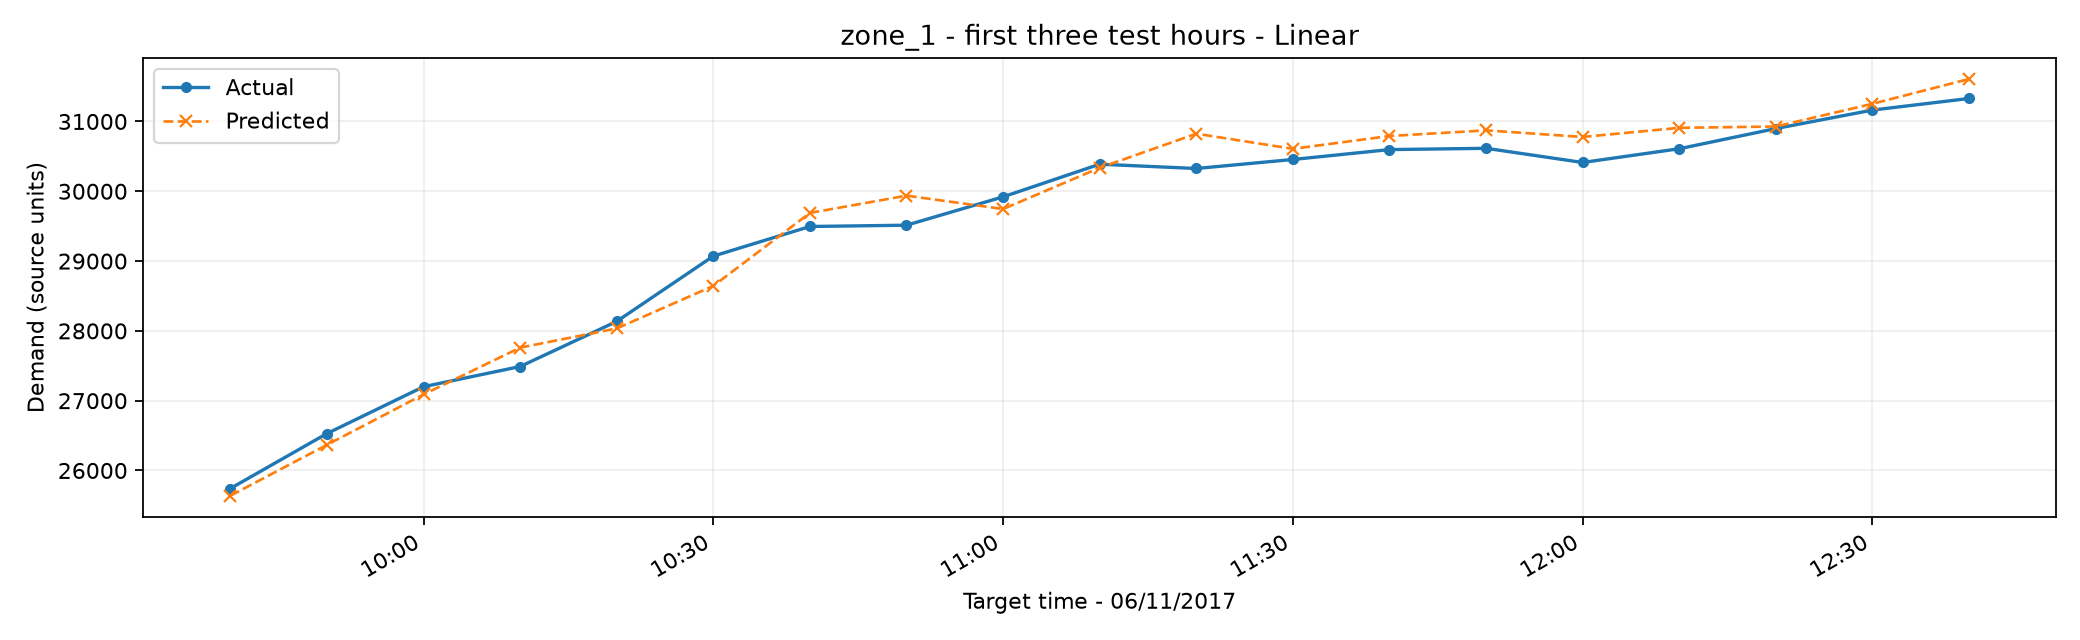

In [ ]:
from matplotlib.dates import DateFormatter
shown = timeline[timeline['Target time'] <= timeline['Target time'].iloc[0] + pd.Timedelta(hours=3)]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(shown['Target time'], shown['Actual'], label='Actual', linewidth=1.5, marker='o', markersize=4)
ax.plot(shown['Target time'], shown['Predicted'], label='Predicted', linewidth=1.2, linestyle='--', marker='x', markersize=5)
ax.set(title=f'{plot_zone} - first three test hours - {best_name}', xlabel='Target time - ' + shown['Target time'].iloc[0].strftime('%d/%m/%Y'), ylabel='Demand (source units)')
ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))
ax.grid(alpha=0.2)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig('next_step_forecast_3h.png', dpi=160)
plt.show()


### First 24 hours
Show the daily demand cycle with 145 observations, including both endpoints.


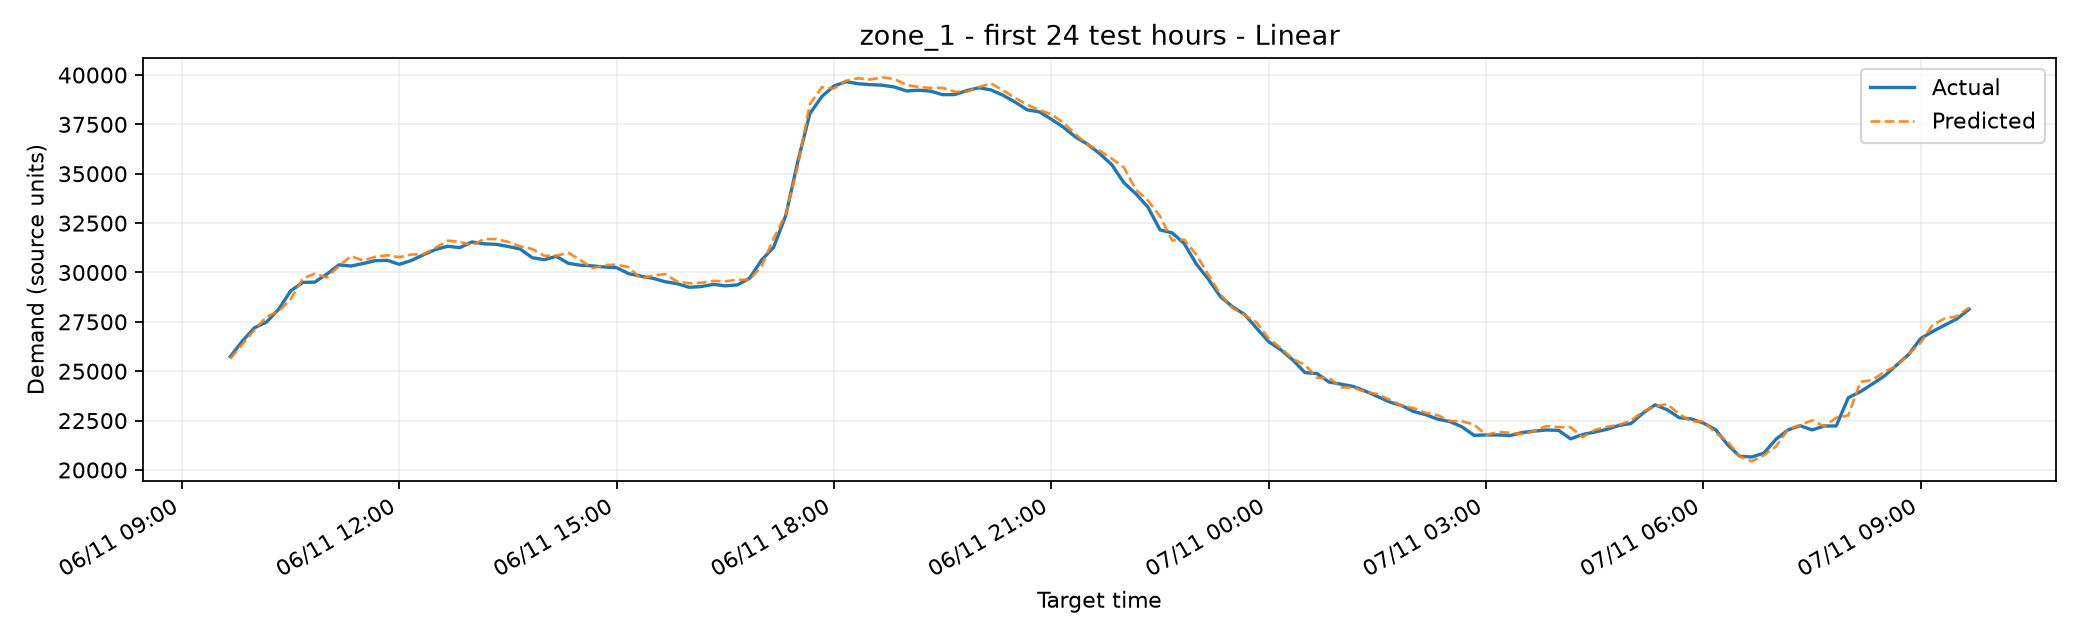

In [ ]:
from matplotlib.dates import DateFormatter
shown_day = timeline[timeline['Target time'] <= timeline['Target time'].iloc[0] + pd.Timedelta(days=1)]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(shown_day['Target time'], shown_day['Actual'], label='Actual', linewidth=1.5)
ax.plot(shown_day['Target time'], shown_day['Predicted'], label='Predicted', linewidth=1.2, linestyle='--', alpha=0.9)
ax.set(title=f'{plot_zone} - first 24 test hours - {best_name}', xlabel='Target time', ylabel='Demand (source units)')
ax.xaxis.set_major_formatter(DateFormatter('%d/%m %H:%M'))
ax.grid(alpha=0.2)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig('next_step_forecast_1day.png', dpi=160)
plt.show()


### Full test period
Show all 7,862 target timestamps from November 6 to December 30. Use the zoomed views to inspect local errors.


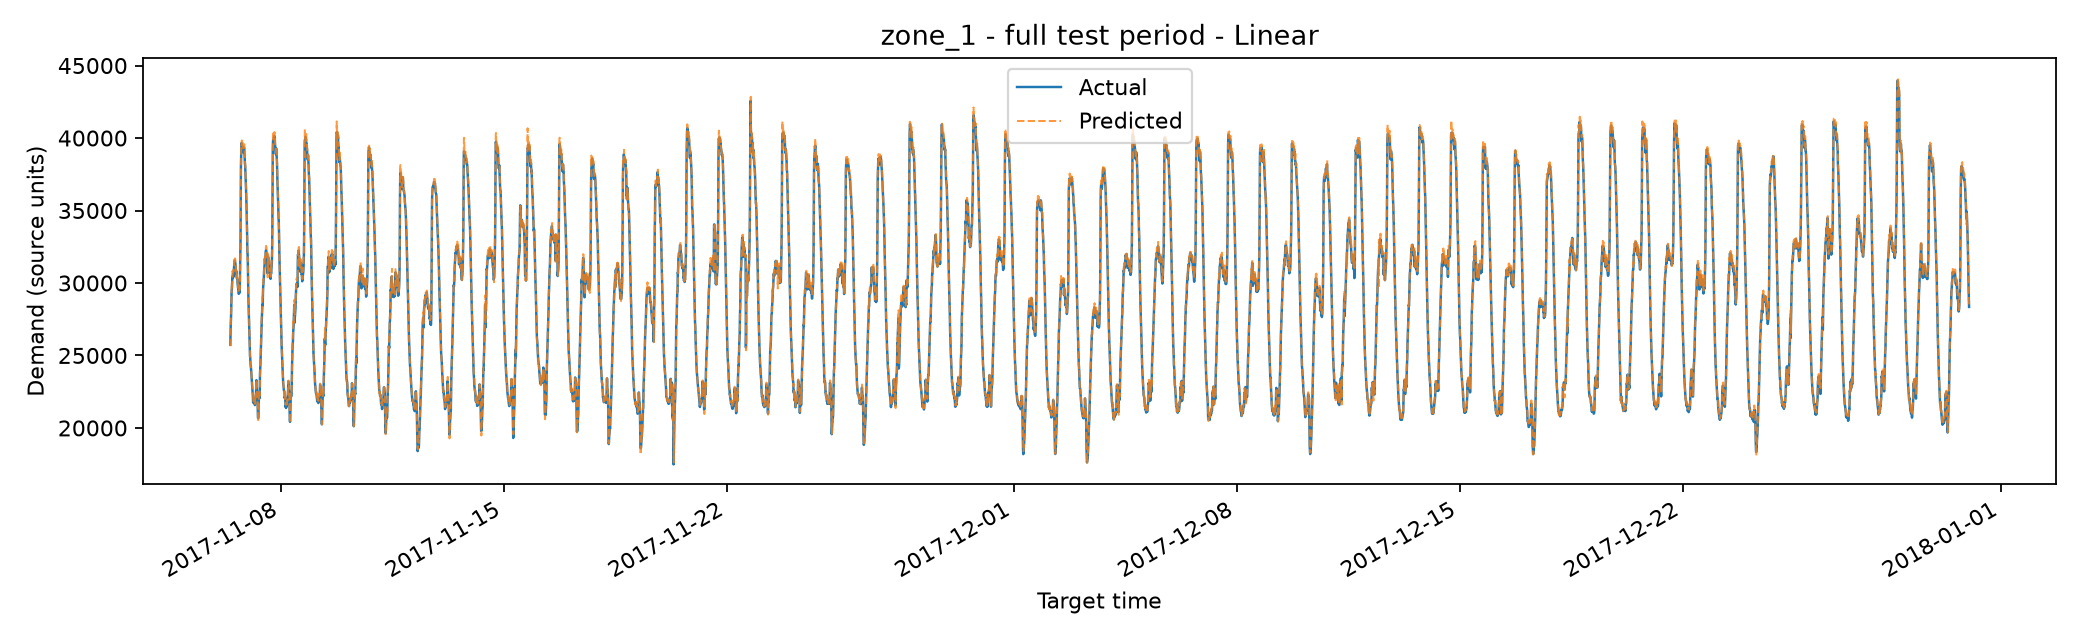

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(timeline['Target time'], timeline['Actual'], label='Actual', linewidth=1.1)
ax.plot(timeline['Target time'], timeline['Predicted'], label='Predicted', linewidth=0.9, linestyle='--', alpha=0.8)
ax.set(title=f'{plot_zone} - full test period - {best_name}', xlabel='Target time', ylabel='Demand (source units)')
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig('next_step_forecast_full_test.png', dpi=160)
plt.show()


## 13. Export results
Save experiment tables, selected inputs, zone errors and test predictions as CSV files. Export the two error plots and three forecast views.


In [ ]:
feature_ablation.to_csv('feature_ablation_comparison.csv')
delta_results.to_csv('delta_target_comparison.csv')
seasonality.to_csv('seasonality_comparison.csv', index=False)
validation_results.to_csv('validation_model_comparison.csv')
tuning_results.to_csv('tuning_comparison.csv', index=False)
train_test_results.to_csv('train_test_model_comparison.csv')
weekly_mae.to_csv('mae_by_week.csv')
monthly_mae.to_csv('mae_by_month.csv')
forecast_table = pd.DataFrame({'origin': test_origin.to_numpy(), 'target_time': test_target_time.to_numpy()})
for i, zone in enumerate(zones):
    forecast_table[zone + '_actual'] = y_test[zone].to_numpy()
    forecast_table[zone + '_predicted'] = best_test_prediction[:, i]
    forecast_table[zone + '_absolute_error'] = np.abs(y_test[zone].to_numpy() - best_test_prediction[:, i])
forecast_table.to_csv('next_step_predictions.csv', index=False)
print('Selected input groups:')
display(selected_features)
print('Model selected by validation:', best_name)
selected_features.to_csv('feature_selection_by_model.csv')
print('Validation MAE:', validation_results.loc[best_name, 'MAE'])
print('Test MAE:', train_test_results.loc[best_name, 'Test MAE'])
all_results.to_csv('all_experiment_results.csv')
progress_table.to_csv('optimization_progression.csv', index=False)
zone_mae.to_csv('test_mae_by_zone.csv')
print('Saved CSV tables and five figures: mae_by_week.png, mae_by_month.png, next_step_forecast_3h.png, next_step_forecast_1day.png, next_step_forecast_full_test.png.')

arvar_cv_results.to_csv('arvar_lag_order_cv.csv', index=False)
arvar_selected.to_csv('arvar_selected_orders.csv')
arvar_comparison.to_csv('arvar_model_comparison.csv')


## Findings
- Recent history reduces Linear's test MAE from 301.56 to 178.69; weekly inputs bring it to 173.53.
- RF learns demand changes better than demand levels; validation MAE falls by 78.9%.
- Linear and tuned Ridge give nearly identical forecasts. Keep Linear with 49 inputs.

- Linear's test MAE is 16.6% below AR(12) and 23.4% below VAR(12), with lag orders selected by training CV.

Sources: [UCI Tetouan](https://archive.ics.uci.edu/dataset/849/power+consumption+of+tetouan+city), [course requirements](https://docs.google.com/spreadsheets/d/17AhxqqU-uAUvH9RTIqbgO1w13_obfjTln45ukoH7SmM/edit), [group GitHub](https://github.com/huy1907ddddddd/DS66B_group_14).
